# 03 · Modelos predictivos: depresión y ansiedad

Clasificadores sobre la muestra de desarrollo (`outputs/desarrollo.csv`, de `01_datos`):

- **Modelos**: regresión logística, Random Forest, SVM (kernel RBF), MLP y XGBoost. Referencias: clasificador constante (AUC = 0,5) y logística con **solo sexo**, que es la vara que un modelo acústico tiene que superar.
- **Features**: las 20 CORE de cada tarea + sexo (21 columnas), y las 4 tareas concatenadas + sexo (81).
- **Validación cruzada anidada**: k-fold estratificado repetido afuera (5 pliegues × 5 repeticiones) para estimar el desempeño; `GridSearchCV` (5 pliegues) adentro de cada pliegue para elegir hiperparámetros. Así la elección de hiperparámetros nunca ve los datos con que se evalúa.
- **Métrica principal**: AUC (no depende del umbral). Además, exactitud balanceada, sensibilidad y especificidad con el umbral por defecto de cada modelo (`class_weight="balanced"` donde existe).
- **Prueba final** (89 sujetos): sigue sellada; la última sección explica cómo usarla una sola vez.

## Housekeeping

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, permutation_test_score)
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, classification_report
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

%matplotlib inline

In [2]:
# Parámetros
N_FOLDS = 5            # pliegues externos
REPETICIONES = 5       # repeticiones del k-fold externo
SEMILLA = 2026
N_JOBS = 10            # procesos en paralelo (pliegues externos)
N_PERMUTACIONES = 100  # test de permutación del mejor modelo por desenlace (0 = no correr)

datos = pd.read_csv("outputs/desarrollo.csv", dtype={"participant_id": str})
TAREAS = ["DESCRIPCION", "PREGUNTA1", "PREGUNTA2", "TEXTO_EL_ABUELO"]
OBJETIVOS = {"dep": "Depresión (PHQ-9 ≥ 10)", "ans": "Ansiedad (GAD-7 ≥ 10)"}
FEATURES = [c.split("__")[0] for c in datos.columns if c.endswith("__DESCRIPCION") and not c.startswith(("tasa", "duracion"))]

CONJUNTOS = {t: [f"{f}__{t}" for f in FEATURES] + ["sexo"] for t in TAREAS}
CONJUNTOS["CONCATENADO"] = [f"{f}__{t}" for t in TAREAS for f in FEATURES] + ["sexo"]

print(f"Sujetos: {len(datos)} | features por tarea: {len(FEATURES)}")
print({o: f"{datos[o].sum()} casos ({datos[o].mean():.3f})" for o in OBJETIVOS})
print({k: len(v) for k, v in CONJUNTOS.items()})

Sujetos: 356 | features por tarea: 20
{'dep': '140 casos (0.393)', 'ans': '106 casos (0.298)'}
{'DESCRIPCION': 21, 'PREGUNTA1': 21, 'PREGUNTA2': 21, 'TEXTO_EL_ABUELO': 21, 'CONCATENADO': 81}


## 1. Modelos y grillas de hiperparámetros

Cada modelo va en un pipeline: imputación por la mediana (los pocos faltantes de formantes y pausas) → estandarización → clasificador. La imputación y la escala se ajustan solo con el pliegue de entrenamiento.

In [3]:
def modelos(obj):
    y = datos[obj]
    peso_pos = (y == 0).sum() / (y == 1).sum()   # para XGBoost (equivale a class_weight="balanced")
    return {
        "logreg": (LogisticRegression(class_weight="balanced", max_iter=5000),
                   {"C": [0.01, 0.1, 1, 10]}),
        "rf": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEMILLA, n_jobs=1),
               {"max_depth": [3, 6, None], "min_samples_leaf": [1, 5]}),
        "svm": (SVC(kernel="rbf", class_weight="balanced"),
                {"C": [0.1, 1, 10], "gamma": ["scale", 0.01]}),
        "mlp": (MLPClassifier(max_iter=2000, random_state=SEMILLA),
                {"hidden_layer_sizes": [(16,), (32, 16)], "alpha": [1e-3, 1e-1]}),
        "xgb": (XGBClassifier(n_estimators=200, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=peso_pos, eval_metric="logloss", random_state=SEMILLA, n_jobs=1),
                {"max_depth": [2, 3], "min_child_weight": [1, 5]}),
    }

def pipeline(clf):
    return Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()), ("modelo", clf)])

def con_busqueda(clf, grilla):
    if not grilla:
        return pipeline(clf)
    return GridSearchCV(pipeline(clf), {f"modelo__{k}": v for k, v in grilla.items()},
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), scoring="roc_auc", n_jobs=1)

def puntaje(est, X):
    """Puntaje continuo para el AUC: probabilidad si existe, si no la función de decisión (SVM)."""
    return est.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X)

EXTERNO = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=REPETICIONES, random_state=SEMILLA)
METRICAS = {"auc": "roc_auc", "bal_acc": "balanced_accuracy", "sens": "recall",
            "esp": make_scorer(recall_score, pos_label=0)}

## 2. Validación cruzada anidada

Para cada desenlace, conjunto de features y modelo se guardan las métricas de los 25 pliegues externos, los hiperparámetros elegidos en cada pliegue y las predicciones fuera de muestra de la primera repetición (para la matriz de confusión).

In [4]:
def evaluar(est, cols, y):
    X = datos[cols]
    t0 = time.time()
    cv = cross_validate(est, X, y, cv=EXTERNO, scoring=METRICAS, n_jobs=N_JOBS,
                        return_estimator=True, return_indices=True)
    seg = time.time() - t0
    oof_p, oof_y = np.full(len(y), np.nan), np.full(len(y), np.nan)
    for e, idx in zip(cv["estimator"][:N_FOLDS], cv["indices"]["test"][:N_FOLDS]):
        oof_p[idx] = puntaje(e, X.iloc[idx])
        oof_y[idx] = e.predict(X.iloc[idx])
    params = [e.best_params_ for e in cv["estimator"]] if hasattr(cv["estimator"][0], "best_params_") else []
    return {"cv": {k: cv[f"test_{k}"] for k in METRICAS}, "seg": seg, "oof_p": oof_p, "oof_y": oof_y, "params": params}

resultados = {}
t_total = time.time()
for obj, nombre in OBJETIVOS.items():
    y = datos[obj]
    resultados[(obj, "referencia", "constante")] = evaluar(DummyClassifier(strategy="prior"), ["sexo"], y)
    resultados[(obj, "solo_sexo", "logreg")] = evaluar(pipeline(LogisticRegression(class_weight="balanced")), ["sexo"], y)
    for conj, cols in CONJUNTOS.items():
        for nombre_m, (clf, grilla) in modelos(obj).items():
            r = evaluar(con_busqueda(clf, grilla), cols, y)
            resultados[(obj, conj, nombre_m)] = r
            print(f"{obj} | {conj:15s} | {nombre_m:6s} | AUC {r['cv']['auc'].mean():.3f} ± {r['cv']['auc'].std():.3f} | {r['seg']:.0f} s")
print(f"\nTiempo total: {(time.time() - t_total) / 60:.1f} min")

dep | DESCRIPCION     | logreg | AUC 0.588 ± 0.063 | 3 s


dep | DESCRIPCION     | rf     | AUC 0.619 ± 0.060 | 188 s


dep | DESCRIPCION     | svm    | AUC 0.599 ± 0.076 | 3 s


dep | DESCRIPCION     | mlp    | AUC 0.508 ± 0.064 | 155 s


dep | DESCRIPCION     | xgb    | AUC 0.598 ± 0.062 | 18 s


dep | PREGUNTA1       | logreg | AUC 0.578 ± 0.069 | 2 s


... (40 outputs left out)

ans | CONCATENADO     | rf     | AUC 0.506 ± 0.043 | 190 s


ans | CONCATENADO     | svm    | AUC 0.514 ± 0.067 | 4 s


ans | CONCATENADO     | mlp    | AUC 0.460 ± 0.061 | 92 s


ans | CONCATENADO     | xgb    | AUC 0.493 ± 0.055 | 53 s

Tiempo total: 53.9 min


## 3. Resultados

In [5]:
filas = []
for (obj, conj, mod), r in resultados.items():
    fila = {"objetivo": obj, "conjunto": conj, "modelo": mod}
    for k, v in r["cv"].items():
        fila[f"{k}_media"], fila[f"{k}_de"] = v.mean(), v.std()
    fila["segundos"] = r["seg"]
    filas.append(fila)
tabla = pd.DataFrame(filas)
for obj, nombre in OBJETIVOS.items():
    print(f"==================== {nombre}")
    display(tabla[tabla["objetivo"] == obj].drop(columns="objetivo")
            .sort_values("auc_media", ascending=False).round(3).reset_index(drop=True))

==================== Depresión (PHQ-9 ≥ 10)


,conjunto,modelo,auc_media,auc_de,bal_acc_media,bal_acc_de,sens_media,sens_de,esp_media,esp_de,segundos
0,PREGUNTA2,rf,0.635,0.061,0.581,0.055,0.539,0.100,0.623,0.087,143.742
1,DESCRIPCION,rf,0.619,0.060,0.591,0.053,0.524,0.114,0.658,0.081,187.799
2,solo_sexo,logreg,0.619,0.054,0.619,0.054,0.700,0.085,0.537,0.069,0.535
3,PREGUNTA2,xgb,0.614,0.055,0.583,0.042,0.496,0.089,0.671,0.064,15.158
4,PREGUNTA2,svm,0.604,0.069,0.590,0.060,0.623,0.113,0.557,0.073,3.213
5,TEXTO_EL_ABUELO,logreg,0.603,0.060,0.604,0.047,0.654,0.086,0.553,0.072,2.057
6,CONCATENADO,svm,0.601,0.064,0.600,0.052,0.663,0.113,0.537,0.063,3.956
7,DESCRIPCION,svm,0.599,0.076,0.603,0.051,0.691,0.111,0.514,0.077,3.151
8,DESCRIPCION,xgb,0.598,0.062,0.568,0.050,0.464,0.100,0.672,0.077,18.364
9,CONCATENADO,rf,0.595,0.066,0.581,0.052,0.551,0.128,0.610,0.095,192.018


==================== Ansiedad (GAD-7 ≥ 10)


,conjunto,modelo,auc_media,auc_de,bal_acc_media,bal_acc_de,sens_media,sens_de,esp_media,esp_de,segundos
0,solo_sexo,logreg,0.581,0.060,0.581,0.060,0.670,0.093,0.492,0.058,0.137
1,PREGUNTA2,rf,0.541,0.054,0.518,0.043,0.243,0.118,0.793,0.131,142.745
2,DESCRIPCION,svm,0.539,0.075,0.514,0.048,0.469,0.343,0.559,0.316,3.317
3,PREGUNTA1,svm,0.538,0.074,0.517,0.037,0.479,0.281,0.554,0.278,3.069
4,PREGUNTA2,mlp,0.536,0.059,0.512,0.051,0.266,0.089,0.757,0.074,154.823
5,PREGUNTA2,svm,0.535,0.058,0.520,0.041,0.477,0.205,0.563,0.156,3.482
6,TEXTO_EL_ABUELO,svm,0.531,0.067,0.524,0.042,0.475,0.280,0.573,0.246,2.840
7,PREGUNTA2,xgb,0.529,0.058,0.513,0.051,0.315,0.087,0.712,0.079,13.752
8,DESCRIPCION,xgb,0.529,0.050,0.525,0.051,0.331,0.089,0.718,0.059,13.679
9,DESCRIPCION,rf,0.528,0.050,0.502,0.050,0.260,0.136,0.743,0.120,142.952


AUC media (25 pliegues externos) por conjunto de features y modelo. La línea de comparación es la logística con solo sexo:

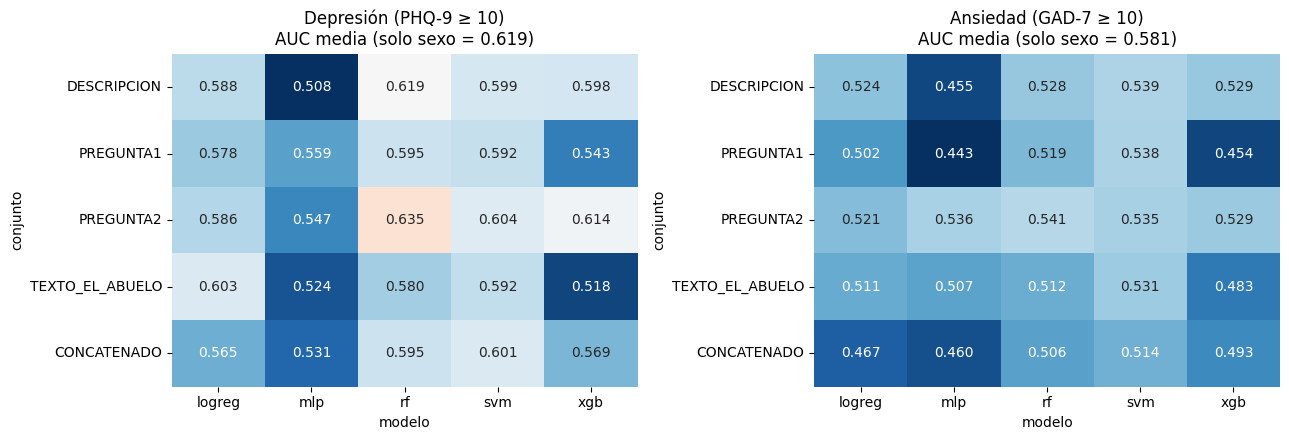

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, (obj, nombre) in zip(ax, OBJETIVOS.items()):
    t = tabla[(tabla["objetivo"] == obj) & tabla["conjunto"].isin(list(CONJUNTOS))]
    mapa = t.pivot(index="conjunto", columns="modelo", values="auc_media").loc[list(CONJUNTOS)]
    ref = tabla.query("objetivo == @obj and conjunto == 'solo_sexo'")["auc_media"].iloc[0]
    sns.heatmap(mapa, annot=True, fmt=".3f", cmap="RdBu_r", center=ref, ax=a, cbar=False)
    a.set_title(f"{nombre}\nAUC media (solo sexo = {ref:.3f})")
plt.tight_layout(); plt.show()

Distribución del AUC en los 25 pliegues de las 5 mejores configuraciones de cada desenlace, junto a las referencias:

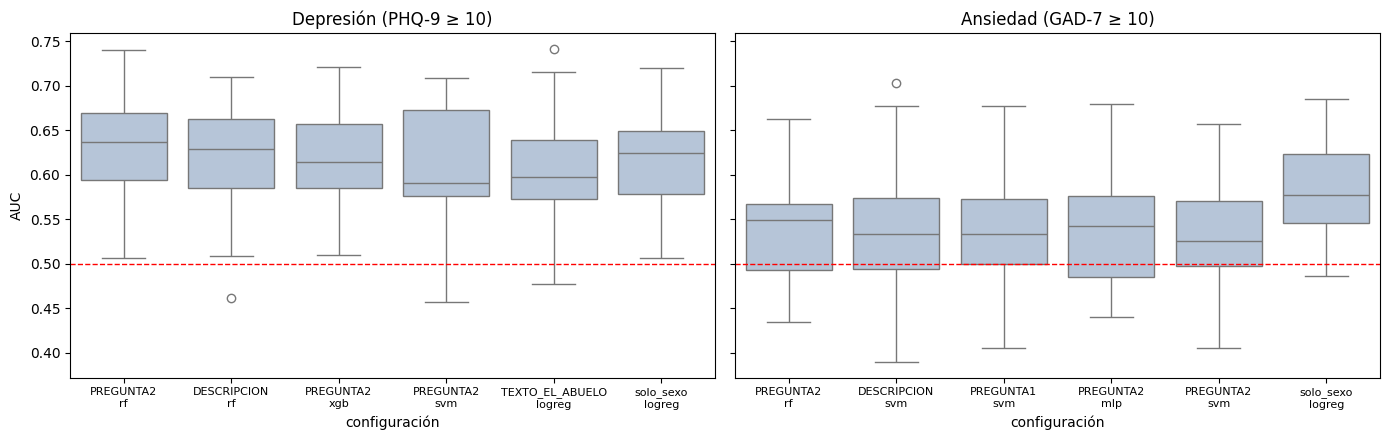

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a, (obj, nombre) in zip(ax, OBJETIVOS.items()):
    t = tabla[(tabla["objetivo"] == obj) & tabla["conjunto"].isin(list(CONJUNTOS))].nlargest(5, "auc_media")
    claves = [(obj, c, m) for c, m in zip(t["conjunto"], t["modelo"])] + [(obj, "solo_sexo", "logreg")]
    largo = pd.DataFrame([(f"{c}\n{m}", v) for (_, c, m) in claves for v in resultados[(obj, c, m)]["cv"]["auc"]],
                         columns=["configuración", "AUC"])
    sns.boxplot(data=largo, x="configuración", y="AUC", ax=a, color="lightsteelblue")
    a.axhline(0.5, color="red", ls="--", lw=1); a.set_title(nombre); a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

Hiperparámetros elegidos con más frecuencia en los 25 pliegues (si cambian mucho entre pliegues, la grilla no es estable):

In [8]:
for obj in OBJETIVOS:
    t = tabla[(tabla["objetivo"] == obj) & tabla["conjunto"].isin(list(CONJUNTOS))].nlargest(5, "auc_media")
    for c, m in zip(t["conjunto"], t["modelo"]):
        frec = pd.Series([str(p) for p in resultados[(obj, c, m)]["params"]]).value_counts()
        print(f"{obj} | {c} | {m}: {frec.index[0]} ({frec.iloc[0]}/25)")

dep | PREGUNTA2 | rf: {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5} (11/25)
dep | DESCRIPCION | rf: {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5} (9/25)
dep | PREGUNTA2 | xgb: {'modelo__max_depth': 2, 'modelo__min_child_weight': 5} (10/25)
dep | PREGUNTA2 | svm: {'modelo__C': 0.1, 'modelo__gamma': 'scale'} (16/25)
dep | TEXTO_EL_ABUELO | logreg: {'modelo__C': 0.01} (16/25)
ans | PREGUNTA2 | rf: {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 1} (10/25)
ans | DESCRIPCION | svm: {'modelo__C': 0.1, 'modelo__gamma': 0.01} (13/25)
ans | PREGUNTA1 | svm: {'modelo__C': 0.1, 'modelo__gamma': 'scale'} (18/25)
ans | PREGUNTA2 | mlp: {'modelo__alpha': 0.1, 'modelo__hidden_layer_sizes': (32, 16)} (10/25)
ans | PREGUNTA2 | svm: {'modelo__C': 0.1, 'modelo__gamma': 'scale'} (13/25)


## 4. Mejor configuración por desenlace

Matriz de confusión y reporte de clasificación con las predicciones fuera de muestra de la primera repetición (cada sujeto predicho una vez):

==================== Depresión (PHQ-9 ≥ 10): PREGUNTA2 · rf
              precision    recall  f1-score   support

     no caso      0.672     0.606     0.637       216
        caso      0.472     0.543     0.505       140

    accuracy                          0.581       356
   macro avg      0.572     0.575     0.571       356
weighted avg      0.593     0.581     0.585       356

==================== Ansiedad (GAD-7 ≥ 10): PREGUNTA2 · rf
              precision    recall  f1-score   support

     no caso      0.701     0.752     0.726       250
        caso      0.295     0.245     0.268       106

    accuracy                          0.601       356
   macro avg      0.498     0.499     0.497       356
weighted avg      0.581     0.601     0.590       356



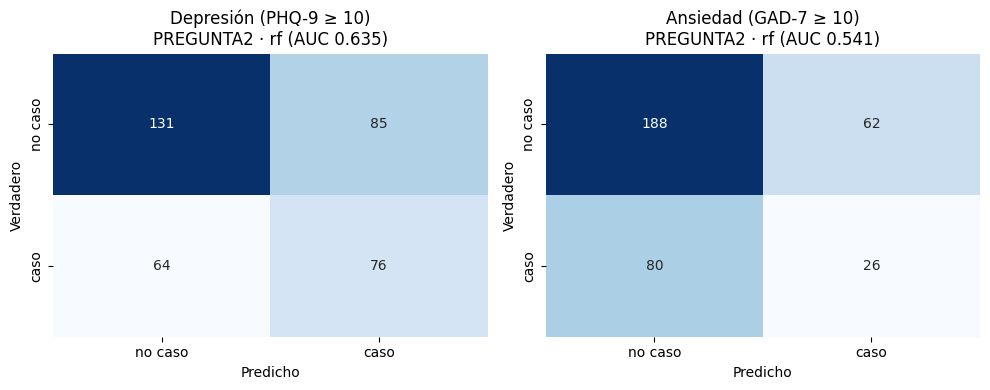

In [9]:
mejores = {}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (obj, nombre) in zip(ax, OBJETIVOS.items()):
    t = tabla[(tabla["objetivo"] == obj) & tabla["conjunto"].isin(list(CONJUNTOS))]
    fila = t.loc[t["auc_media"].idxmax()]
    mejores[obj] = (fila["conjunto"], fila["modelo"])
    r = resultados[(obj, fila["conjunto"], fila["modelo"])]
    y = datos[obj]
    cm = confusion_matrix(y, r["oof_y"].astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=a, cbar=False,
                xticklabels=["no caso", "caso"], yticklabels=["no caso", "caso"])
    a.set_xlabel("Predicho"); a.set_ylabel("Verdadero")
    a.set_title(f"{nombre}\n{fila['conjunto']} · {fila['modelo']} (AUC {fila['auc_media']:.3f})")
    print(f"==================== {nombre}: {fila['conjunto']} · {fila['modelo']}")
    print(classification_report(y, r["oof_y"].astype(int), target_names=["no caso", "caso"], digits=3))
plt.tight_layout(); plt.show()

## 5. Test de permutación del mejor modelo

Se permutan las etiquetas y se repite toda la validación (con la búsqueda de hiperparámetros adentro) para ver qué AUC se obtiene por azar. Ojo: el mejor modelo se eligió entre 25 configuraciones por desenlace, así que el valor p de una sola configuración es optimista; la comparación más honesta es contra la logística con solo sexo y contra el resto de la tabla.

Depresión (PHQ-9 ≥ 10) · PREGUNTA2 · rf: AUC 0.625 | nulo: media 0.505, p95 0.569 | p = 0.010 | 2806 s


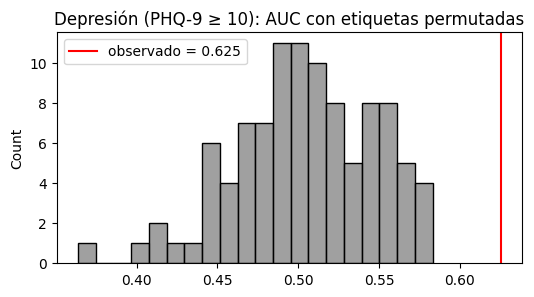

Ansiedad (GAD-7 ≥ 10) · PREGUNTA2 · rf: AUC 0.501 | nulo: media 0.510, p95 0.590 | p = 0.584 | 2098 s


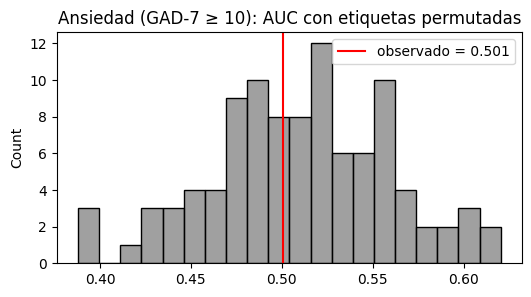

In [10]:
permutaciones = {}
if N_PERMUTACIONES > 0:
    for obj, nombre in OBJETIVOS.items():
        conj, mod = mejores[obj]
        clf, grilla = modelos(obj)[mod]
        t0 = time.time()
        auc, auc_perm, p = permutation_test_score(
            con_busqueda(clf, grilla), datos[CONJUNTOS[conj]], datos[obj],
            cv=StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEMILLA), scoring="roc_auc",
            n_permutations=N_PERMUTACIONES, n_jobs=N_JOBS, random_state=SEMILLA)
        permutaciones[obj] = auc_perm
        print(f"{nombre} · {conj} · {mod}: AUC {auc:.3f} | nulo: media {auc_perm.mean():.3f}, "
              f"p95 {np.percentile(auc_perm, 95):.3f} | p = {p:.3f} | {time.time() - t0:.0f} s")
        plt.figure(figsize=(6, 3))
        sns.histplot(auc_perm, bins=20, color="grey")
        plt.axvline(auc, color="red", label=f"observado = {auc:.3f}")
        plt.title(f"{nombre}: AUC con etiquetas permutadas"); plt.legend(); plt.show()

## 6. Guardar resultados

In [11]:
tabla.to_csv("outputs/predictivo_resumen.csv", index=False)
pd.DataFrame([{"objetivo": o, "conjunto": c, "modelo": m, "pliegue": i, **{k: v[i] for k, v in r["cv"].items()}}
              for (o, c, m), r in resultados.items() for i in range(N_FOLDS * REPETICIONES)]
             ).to_csv("outputs/predictivo_pliegues.csv", index=False)
print("Guardados: outputs/predictivo_resumen.csv, outputs/predictivo_pliegues.csv")

Guardados: outputs/predictivo_resumen.csv, outputs/predictivo_pliegues.csv


## 7. Prueba final (sellada)

Se usa **una sola vez**, cuando el modelo (desenlace, tarea o conjunto, algoritmo e hiperparámetros) esté fijado a partir de los resultados de desarrollo. Mientras `EVALUAR_PRUEBA_FINAL = False`, esta celda no lee las etiquetas de la prueba final.

In [12]:
EVALUAR_PRUEBA_FINAL = False
MODELO_FINAL = None   # p. ej. ("dep", "PREGUNTA1", "svm"); se fija antes de cambiar la bandera

if EVALUAR_PRUEBA_FINAL:
    from sklearn.metrics import roc_auc_score
    obj, conj, mod = MODELO_FINAL
    feat = pd.read_csv("../feature-extraction-UA/outputs/features_core_completos.csv", dtype={"participant_id": str})
    prueba_ids = pd.read_csv("prueba_final_ids.csv", dtype={"participant_id": str})["participant_id"]
    feat = feat[feat["participant_id"].isin(prueba_ids)]
    ancha = feat.pivot(index="participant_id", columns="task", values=FEATURES)
    ancha.columns = [f"{f}__{t}" for f, t in ancha.columns]
    etq = pd.read_excel("../baseDatos_tabular.xlsx")
    etq["participant_id"] = etq["cualestucodigo"].astype(int).astype(str).str.zfill(3)
    etq["dep"], etq["ans"] = (etq["TOTALPHQ9"] >= 10).astype(int), (etq["TOTALGAD7"] >= 10).astype(int)
    etq["sexo"] = (etq["SEXO"] == 2).astype(int)
    prueba = etq.set_index("participant_id")[["dep", "ans", "sexo"]].join(ancha, how="inner")
    clf, grilla = modelos(obj)[mod]
    final = con_busqueda(clf, grilla).fit(datos[CONJUNTOS[conj]], datos[obj])
    p = puntaje(final, prueba[CONJUNTOS[conj]])
    print(f"Prueba final (n = {len(prueba)}): AUC = {roc_auc_score(prueba[obj], p):.3f}")
    print(classification_report(prueba[obj], final.predict(prueba[CONJUNTOS[conj]]), digits=3))
else:
    print("Prueba final sellada: no se evaluó.")

Prueba final sellada: no se evaluó.


## Lectura de resultados

**Referencias**
- Solo sexo (logística): AUC 0,619 en depresión y 0,581 en ansiedad. La constante da 0,500.

**Depresión**
- Mejor configuración: bosque aleatorio con PREGUNTA2, AUC 0,635 ± 0,061. Le siguen el bosque con DESCRIPCION (0,619) y XGBoost con PREGUNTA2 (0,614).
- Solo 1 de las 25 configuraciones supera en promedio a la logística con solo sexo: el mismo bosque con PREGUNTA2, por 0,017 de AUC, y lo hace en 18 de los 25 pliegues. Esa diferencia es menor que la desviación estándar entre pliegues (~0,06), y el modelo se eligió entre 25.
- Con las predicciones fuera de muestra de la primera repetición, el bosque con PREGUNTA2 tiene una sensibilidad de 0,543 y una especificidad de 0,606. En los 25 pliegues, la exactitud balanceada de la logística con solo sexo es mayor (0,619 frente a 0,581).

**Ansiedad**
- Ninguna de las 25 configuraciones supera a la logística con solo sexo. La mejor (bosque con PREGUNTA2) llega a AUC 0,541, 0,039 por debajo de la de solo sexo.
- Varias configuraciones quedan bajo 0,5 (la red neuronal en DESCRIPCION y PREGUNTA1, la logística con las 4 tareas concatenadas): con estos datos, agregar las features empeora el modelo.

**Por modelo y conjunto**
- La red neuronal es la peor en 6 de los 10 pares desenlace × conjunto.
- Concatenar las 4 tareas (81 columnas) no mejora a la mejor tarea por separado, en ninguno de los dos desenlaces.
- Los hiperparámetros elegidos cambian mucho entre pliegues: el más frecuente aparece en 9 a 18 de los 25. Casi siempre ganan los valores más regularizados (árboles de profundidad 3, C = 0,01 o 0,1).

**Test de permutación (100 permutaciones, 5 pliegues)**
- Depresión, bosque con PREGUNTA2: AUC 0,625, nulo con media 0,505 y percentil 95 de 0,569, p = 0,010.
- Ansiedad, bosque con PREGUNTA2: AUC 0,501, p = 0,584.
- **Ojo**: al permutar las etiquetas también se rompe su relación con el sexo, que está en el modelo. El p = 0,010 de depresión dice que el modelo es mejor que el azar, no que la voz aporte por sobre el sexo; eso coincide con lo que da el sexo solo (AUC 0,619). Para medir el aporte de la voz habría que permutar las features acústicas dentro de cada sexo y dejar fijas las etiquetas.

**Tiempo**: 54 min la validación anidada y 82 min el test de permutación (10 procesos).

**En resumen**: con n = 356, las 20 features CORE no mejoran la predicción de depresión ni de ansiedad por sobre el sexo, lo mismo que se vio en `02_explicativo`.